In [34]:
from tqdm import tqdm
import numpy as np
import pandas as pd
from netCDF4 import Dataset

ds = Dataset('/nas/cee-ice/data/Confluence_Runs/version 3_0_0/na_sword_v16_SOS_results.nc')

ds
# ds.groups['momma'].variables['stage'][:]

<class 'netCDF4.Dataset'>
root group (NETCDF4 data model, file format HDF5):
    title: SWOT discharge prior information and processing outputs
    summary: All of the outputs from all processes used to generate SWOT discharge products.
    keywords: GCMD:Rivers/Streams, GCMD:Discharge/Flow, GCMD:SWOT
    keywords_vocabulary: NASA Global Change Master Directory (GCMD) Science Keywords
    doi: 10.5067/SWOT-SOS-V1
    id: SWOT_L4_DAWG_SOS_DISCHARGE
    naming_authority: gov.nasa
    standard_name_vocabulary: CF Standard Name Table v72
    featureType: timeseries
    platform: SWOT
    platform_vocabulary: GCMD platform keywords
    instrument: KaRIn
    instrument_vocabulary: GCMD instrument keywords
    processing_level: L4
    conventions: CF-1.8, ACDD-1.3
    acknowledgement: NASA AIST Program Grant Number 80NSSC22K1487, NASA SWOT Science Team Grant Numbers: 80NSSC20K1143, 80NSSC20K1141, 80NSSC20K1340 and CNES SWOT TOSCA fund for the SWOT DAHM project. Additional support from PO.DAAC

In [29]:
ds['reaches']['reach_id'][:]

masked_array(data=[71120000013, 71120000043, 71120000053, ...,
                   73120001026, 73120001036, 73120001046],
             mask=False,
       fill_value=999999)

In [7]:
svs_ds = Dataset("/nas/cee-water/cjgleason/ted/swot-ml/data/SVS_v1_0.5_trans_v17.nc")
svs_ds

<class 'netCDF4.Dataset'>
root group (NETCDF4 data model, file format HDF5):
    title: SWOT Validation Set (SVS)
    summary: Daily in situ river discharge time series and metadata (2023–2025) for SWOT discharge validation.
    creator_name: Peyman Saemian
    contact: Peyman Saemian (saemian@gis.uni-stuttgart.de), Mohammad J. Tourian (tourian@gis.uni-stuttgart.de)
    institution: Institute of Geodesy, University of Stuttgart
    version: 1.0
    license: CC-BY 4.0
    history: Created on 2025-12-12 using MATLAB 25.1.0.2973910 (R2025a) Update 1
    dimensions(sizes): station(3643), time(1096), ymd(3), strlen_station(15), string1(1), strlen_source(7), strlen_rivername(35), num_rchs(8)
    variables(dimensions): float64 Q(station, time), float64 lat(station), float64 lon(station), float64 reach_id_v16(station), int16 date_ymd(ymd, time), |S1 station_id(strlen_station, station, string1), |S1 source(strlen_source, station, string1), |S1 river_name_sword(strlen_rivername, station, string1

In [58]:
ymd_arr = svs_ds['date_ymd'][:].data
dt = pd.to_datetime({
    "year": ymd_arr[0],
    "month": ymd_arr[1],
    "day": ymd_arr[2],
})
dt

0      2023-01-01
1      2023-01-02
2      2023-01-03
3      2023-01-04
4      2023-01-05
          ...    
1091   2025-12-27
1092   2025-12-28
1093   2025-12-29
1094   2025-12-30
1095   2025-12-31
Length: 1096, dtype: datetime64[ns]

In [59]:
swot_dir = Path('/nas/cee-ice/data/Confluence_Runs/global_vD/global_vD_mnt/input/swot')

In [65]:
svs_reaches = svs_ds['reach_id_v17'][:,0].data

for idx, reach_id in tqdm(enumerate(svs_reaches)):
    if not np.isfinite(reach_id):
        continue
    reach_id = int(reach_id)
    
    reach_file = swot_dir / f"{reach_id}_SWOT.nc"
    swot_ds = Dataset(reach_file)
    
    break

    

0it [00:00, ?it/s]


In [69]:
list(swot_ds['reach'].variables.keys())

['reach_id',
 'time',
 'time_str',
 'd_x_area',
 'd_x_area_u',
 'slope',
 'slope_u',
 'slope_r_u',
 'slope2',
 'slope2_u',
 'slope2_r_u',
 'width',
 'p_width',
 'width_u',
 'wse',
 'wse_u',
 'wse_r_u',
 'p_length',
 'reach_q',
 'reach_q_b',
 'dark_frac',
 'ice_clim_f',
 'ice_dyn_f',
 'partial_f',
 'n_good_nod',
 'obs_frac_n',
 'xovr_cal_q',
 'xtrk_dist']

In [74]:
swot_ds['reach']['time'][:]

masked_array(data=[7.33395217e+08, 7.33738568e+08, 7.33824405e+08,
                   7.33910243e+08, 7.33996081e+08, 7.34081919e+08,
                   7.34167757e+08, 7.34253595e+08, 7.34339433e+08,
                   7.34425272e+08, 7.34511110e+08, 7.34596948e+08,
                   7.34682786e+08, 7.34768624e+08, 7.34940300e+08,
                   7.35026137e+08, 7.35111975e+08, 7.35197813e+08,
                   7.35283651e+08, 7.35369489e+08, 7.35455327e+08,
                   7.35541165e+08, 7.35627003e+08, 7.35712840e+08,
                   7.35798678e+08, 7.35884516e+08, 7.35970354e+08,
                   7.36056192e+08, 7.36142030e+08, 7.36227868e+08,
                   7.36313705e+08, 7.36399543e+08, 7.36485381e+08,
                   7.36571218e+08, 7.36657056e+08, 7.36742894e+08,
                   7.36828732e+08, 7.36914569e+08, 7.37000407e+08,
                   7.37086245e+08, 7.37172083e+08, 7.37257920e+08,
                   7.37343758e+08, 7.37429596e+08, 7.37515433e

In [36]:
for reach_stage in ds.groups['momma']['Y'][:]:
    mask = reach_stage != -999999999999.0
    if sum(mask) > 5:
        break

reach_stage[mask]

array([0.51376667, 0.4667    , 0.3335    , 1.15216667, 0.90523333,
       0.73323333, 0.79176667, 0.69343333, 0.70523333, 0.77963333,
       0.3835    , 0.8477    , 0.8315    ])

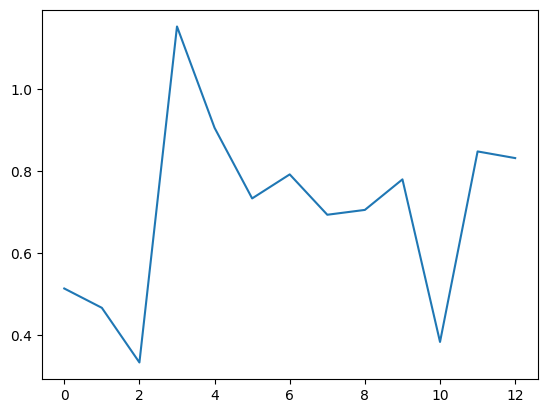

In [37]:
import matplotlib.pyplot as plt

plt.plot(reach_stage[mask])

In [46]:
from pathlib import Path

reach_file = next(Path('/nas/cee-ice/data/Confluence_Runs/global_vD/global_vD_mnt/input/swot').glob('*'))
print(reach_file)

/nas/cee-ice/data/Confluence_Runs/global_vD/global_vD_mnt/input/swot/14277800021_SWOT.nc


In [47]:
ds = Dataset(reach_file)
print(ds)

<class 'netCDF4.Dataset'>
root group (NETCDF4 data model, file format HDF5):
    dimensions(sizes): nt(109), nx(93), nchars(10)
    variables(dimensions): int32 nt(nt), int32 nx(nx), |S1 observations(nt, nchars)
    groups: reach, node


In [48]:
ds['reach']

<class 'netCDF4.Group'>
group /reach:
    dimensions(sizes): chartime(20)
    variables(dimensions): int64 reach_id(), float64 time(nt), |S1 time_str(nt, chartime), float64 d_x_area(nt), float64 d_x_area_u(nt), float64 slope(nt), float64 slope_u(nt), float64 slope_r_u(nt), float64 slope2(nt), float64 slope2_u(nt), float64 slope2_r_u(nt), float64 width(nt), float64 p_width(nt), float64 width_u(nt), float64 wse(nt), float64 wse_u(nt), float64 wse_r_u(nt), float64 p_length(nt), int32 reach_q(nt), int32 reach_q_b(nt), float64 dark_frac(nt), int32 ice_clim_f(nt), int32 ice_dyn_f(nt), int32 partial_f(nt), int32 n_good_nod(nt), float64 obs_frac_n(nt), int32 xovr_cal_q(nt), float64 xtrk_dist(nt)
    groups: hwfit

In [55]:
ds['reach']

<class 'netCDF4.Group'>
group /reach:
    dimensions(sizes): chartime(20)
    variables(dimensions): int64 reach_id(), float64 time(nt), |S1 time_str(nt, chartime), float64 d_x_area(nt), float64 d_x_area_u(nt), float64 slope(nt), float64 slope_u(nt), float64 slope_r_u(nt), float64 slope2(nt), float64 slope2_u(nt), float64 slope2_r_u(nt), float64 width(nt), float64 p_width(nt), float64 width_u(nt), float64 wse(nt), float64 wse_u(nt), float64 wse_r_u(nt), float64 p_length(nt), int32 reach_q(nt), int32 reach_q_b(nt), float64 dark_frac(nt), int32 ice_clim_f(nt), int32 ice_dyn_f(nt), int32 partial_f(nt), int32 n_good_nod(nt), float64 obs_frac_n(nt), int32 xovr_cal_q(nt), float64 xtrk_dist(nt)
    groups: hwfit

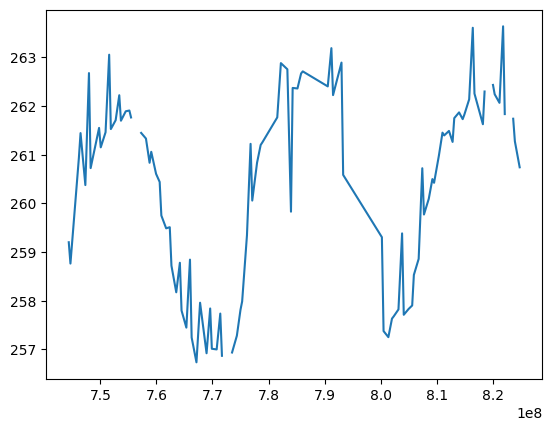

In [56]:
import matplotlib.pyplot as plt

t = ds['reach']['time'][:]
da = ds['reach']['wse'][:]

plt.plot(t,da)

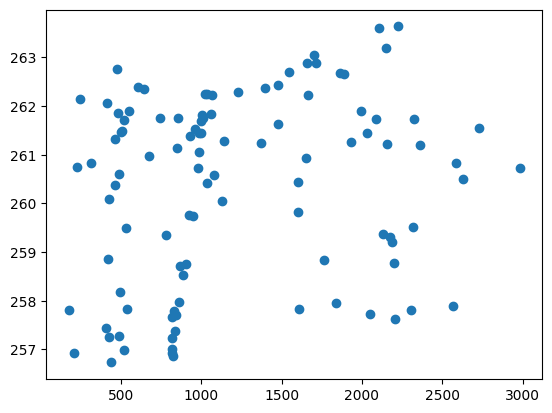

In [55]:
h = ds['reach']['wse'][:]
w = ds['reach']['width'][:]

plt.scatter(w, h)